# 6.1 Simple RNN network in PyTorch

In [8]:
import torch
import torch.nn as nn

class SimpleRNN(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers):
        super().__init__()
        self.rnn = nn.RNN(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1) # Output layer

    def forward(self, x, h0):
        out, hn = self.rnn(x, h0)
        out = self.fc(out[:, -1, :]) # Use the last time step's output
        return out, hn

# Hyperparameters
input_size = 10
hidden_size = 20
num_layers = 1
sequence_length = 5
batch_size = 3

# Create the model
model = SimpleRNN(input_size, hidden_size, num_layers)

# Example input sequence (batch_size, sequence_length, input_size)
input_seq = torch.randn(batch_size, sequence_length, input_size)

# Initial hidden state (num_layers, batch_size, hidden_size)
h0 = torch.zeros(num_layers, batch_size, hidden_size)

# Forward pass through the RNN
output, hn = model(input_seq, h0)
print("Input shape:", input_seq.shape)
print("Output shape:", output.shape)
print("Hidden state shape:", hn.shape)

# Example of using the model for a simple prediction task
x = torch.randn(1, sequence_length, input_size)  # Single sample
h0 = torch.zeros(num_layers, 1, hidden_size)
prediction, _ = model(x, h0)
print("Prediction:", prediction.item())

Input shape: torch.Size([3, 5, 10])
Output shape: torch.Size([3, 1])
Hidden state shape: torch.Size([1, 3, 20])
Prediction: -0.019854899495840073


# 6.2 LSTM in PyTorch

In [9]:
import torch
import torch.nn as nn

class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, output_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        out, (hn, cn) = self.lstm(x, (h0, c0))
        out = self.fc(out[:, -1, :])
        return out, (hn, cn)

# Hyperparameters
input_size = 10
hidden_size = 20
num_layers = 2
output_size = 1
sequence_length = 5
batch_size = 3

# Create model instance
model = LSTMModel(input_size, hidden_size, num_layers, output_size)

# Example input sequence
input_seq = torch.randn(batch_size, sequence_length, input_size)

# Forward pass
output, (hn, cn) = model(input_seq)

# Print shapes
print("Input shape:", input_seq.shape)
print("Output shape:", output.shape)
print("Hidden state shape:", hn.shape)
print("Cell state shape:", cn.shape)

# Example of using the model for a simple prediction task
x = torch.randn(1, sequence_length, input_size)  # Single sample
prediction, _ = model(x)
print("Prediction:", prediction.item())

Input shape: torch.Size([3, 5, 10])
Output shape: torch.Size([3, 1])
Hidden state shape: torch.Size([2, 3, 20])
Cell state shape: torch.Size([2, 3, 20])
Prediction: 0.20730344951152802


# 6.3 GRU in PyTorch

In [10]:
import torch
import torch.nn as nn

class GRUModel(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, output_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.gru = nn.GRU(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        out, _ = self.gru(x, h0)
        out = self.fc(out[:, -1, :])
        return out

# Hyperparameters
input_size = 10
hidden_size = 20
num_layers = 2
output_size = 1
sequence_length = 5
batch_size = 3

# Create model instance
model = GRUModel(input_size, hidden_size, num_layers, output_size)
# Example input sequence
input_seq = torch.randn(batch_size, sequence_length, input_size)
# Forward pass
output = model(input_seq)
# Print shapes
print("Input shape:", input_seq.shape)
print("Output shape:", output.shape)
# Example of using the model for a simple prediction task
x = torch.randn(1, sequence_length, input_size)  # Single sample
prediction = model(x)
print("Prediction:", prediction.item())

Input shape: torch.Size([3, 5, 10])
Output shape: torch.Size([3, 1])
Prediction: 0.044928453862667084


# 6.4 RNN in TensorFlow

In [13]:
import tensorflow as tf
import numpy as np

# Define hyperparameters
batch_size = 32
sequence_length = 10
input_size = 8
hidden_units = 16
output_size = 4

# Create synthetic input data
input_data = tf.random.normal([batch_size, sequence_length, input_size])

# Define an RNN layer
rnn_layer = tf.keras.layers.SimpleRNN(units=hidden_units, return_sequences=True, return_state=True)

# Define a model using the Functional API
inputs = tf.keras.Input(shape=(sequence_length, input_size))
rnn_output, final_state = rnn_layer(inputs)
outputs = tf.keras.layers.Dense(output_size)(rnn_output)
model = tf.keras.Model(inputs=inputs, outputs=[outputs, final_state])

# Compile the model
model.compile(optimizer='adam', loss='mse')

# Generate synthetic target data
target_output = np.random.randn(batch_size, sequence_length, output_size)
target_final_state = np.random.randn(batch_size, hidden_units)

# Train the model
history = model.fit(
    input_data,
    [target_output, target_final_state],
    epochs=5,
    batch_size=batch_size
)

# Make predictions
predictions, final_state_pred = model.predict(input_data)

# Print shapes and sample outputs
print("Input Shape:", input_data.shape)
print("RNN Output Shape:", predictions.shape)
print("RNN Final State Shape:", final_state_pred.shape)
print("Sample Prediction (first sequence, first timestep):")
print(predictions[0, 0])
print("Sample Final State:")
print(final_state_pred[0])

Epoch 1/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 543ms/step - dense_2_loss: 1.8219 - loss: 3.4444 - simple_rnn_2_loss: 1.6225
Epoch 2/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - dense_2_loss: 1.8094 - loss: 3.4286 - simple_rnn_2_loss: 1.6192
Epoch 3/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - dense_2_loss: 1.7971 - loss: 3.4130 - simple_rnn_2_loss: 1.6159
Epoch 4/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - dense_2_loss: 1.7849 - loss: 3.3976 - simple_rnn_2_loss: 1.6126
Epoch 5/5
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - dense_2_loss: 1.7729 - loss: 3.3823 - simple_rnn_2_loss: 1.6093
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
Input Shape: (32, 10, 8)
RNN Output Shape: (32, 10, 4)
RNN Final State Shape: (32, 16)
Sample Prediction (first sequence, first timestep):
[ 0.5138832  -1.0057961  -0.29562974  0.37939382]
Sample Final State:
[-0.6221144   0.46190652 -0.814191    0.9301006  -0.9431395   0.9304459
 -0.94938976  0.3488002  -0.39225787 -0.24078102 -0.6152821  -0.31932858
 -0.90833306  0.4281782  -0.3712296  

# 6.5 LSTM in TensorFlow

In [14]:
import tensorflow as tf
import numpy as np

# Define hyperparameters
batch_size = 32
sequence_length = 10
input_size = 8
hidden_units = 16
output_size = 4

# Create synthetic input data
input_data = tf.random.normal([batch_size, sequence_length, input_size])

# Define an LSTM layer
lstm_layer = tf.keras.layers.LSTM(units=hidden_units, return_sequences=True, return_state=True)

# Define a model using the Functional API
inputs = tf.keras.Input(shape=(sequence_length, input_size))
lstm_output, final_hidden_state, final_cell_state = lstm_layer(inputs)
outputs = tf.keras.layers.Dense(output_size)(lstm_output)
model = tf.keras.Model(inputs=inputs, outputs=[outputs, final_hidden_state, final_cell_state])

# Compile the model
model.compile(optimizer="adam", loss="mse")

# Generate synthetic target data
target_output = np.random.randn(batch_size, sequence_length, output_size)
target_hidden_state = np.random.randn(batch_size, hidden_units)
target_cell_state = np.random.randn(batch_size, hidden_units)

# Train the model
history = model.fit(
    input_data,
    [target_output, target_hidden_state, target_cell_state],
    batch_size=batch_size,
)

# Make predictions
predictions, final_hidden_state_pred, final_cell_state_pred = model.predict(input_data)

# Print shapes and sample outputs
print("Input Shape:", input_data.shape)
print("LSTM Output Shape:", predictions.shape)
print("LSTM Final Hidden State Shape:", final_hidden_state_pred.shape)
print("LSTM Final Cell State Shape:", final_cell_state_pred.shape)
print("Sample Prediction (first sequence, first timestep):")
print(predictions[0, 0])
print("Sample Final Hidden State:")
print(final_hidden_state_pred[0])
print("Sample Final Cell State:")
print(final_cell_state_pred[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 702ms/step - dense_3_loss: 1.0012 - loss: 3.1800 - lstm_loss: 1.0861
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
Input Shape: (32, 10, 8)
LSTM Output Shape: (32, 10, 4)
LSTM Final Hidden State Shape: (32, 16)
LSTM Final Cell State Shape: (32, 16)
Sample Prediction (first sequence, first timestep):
[-0.04893301  0.02643638 -0.05177596 -0.12137796]
Sample Final Hidden State:
[ 0.05735832 -0.0599515   0.0358002  -0.21795502  0.07456477 -0.17328684
  0.08325538  0.11313432  0.12608632  0.3965769   0.09742746  0.08505011
  0.01746651 -0.14707504  0.05491677  0.00092936]
Sample Final Cell State:
[ 0.13344827 -0.11305898  0.0579391  -0.382168    0.15296324 -0.2952064
  0.12320165  0.35031688  0.23145923  0.76213795  0.1567973   0.13702129
  0.04401311 -0.23977083  0.08642275  0.00162598]


# 6.6 RNN in Keras

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_4 (SimpleRNN)        │ (None, 16)             │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 417 (1.63 KB)

 Trainable params: 417 (1.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4825 - loss: 0.7332 - val_accuracy: 0.5750 - val_loss: 0.7121
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4975 - loss: 0.7205 - val_accuracy: 0.5700 - val_loss: 0.7083
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5038 - loss: 0.7120 - val_accuracy: 0.5700 - val_loss: 0.7054
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5088 - loss: 0.7052 - val_accuracy: 0.5500 - val_loss: 0.7035
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5200 - loss: 0.6997 - val_accuracy: 0.5550 - val_loss: 0.7015
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5325 - loss: 0.6954 - val_accuracy: 0.5550 - val_loss: 0.7020
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5425 - loss: 0.6920 - val_accuracy: 0.5400 - val_loss: 0.7017
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5387 - loss: 0.6888 - val_accuracy: 0.5150 - val_loss:

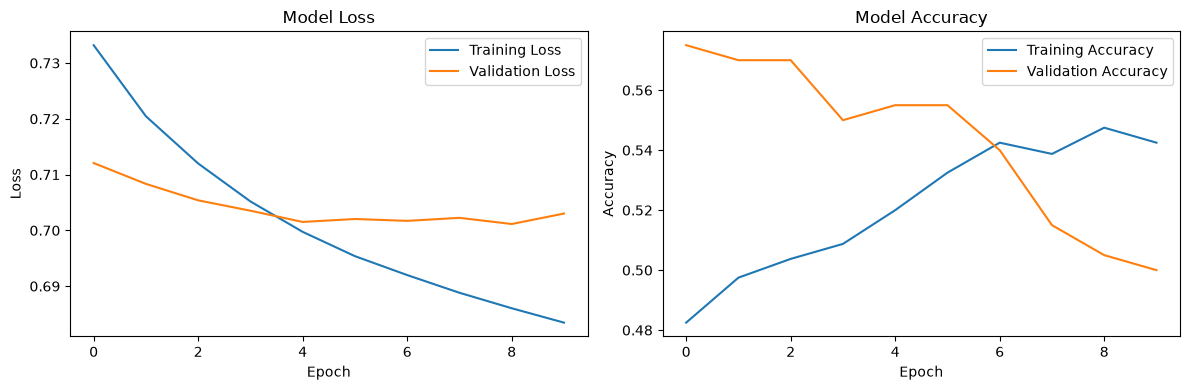

In [17]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Input
import numpy as np
import matplotlib.pyplot as plt

# Define hyperparameters
sequence_length = 10
input_features = 8
hidden_units = 16
output_size = 1
batch_size = 32
epochs = 10

# Generate synthetic data
X = np.random.randn(1000, sequence_length, input_features)
y = np.random.randint(0, 2, (1000, 1)) # Binary classification

# Define a sequential model
model = Sequential([
    Input(shape=(sequence_length, input_features)),
    SimpleRNN(units=hidden_units, return_sequences=False),
    Dense(units=output_size, activation='sigmoid')
])

# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
# Print the model summary
model.summary()
# Train the model
history = model.fit(X, y, batch_size=batch_size, epochs=epochs, validation_split=0.2)
# Evaluate the model
test_loss, test_accuracy = model.evaluate(X, y)
print(f"Test accuracy: {test_accuracy:.4f}")
# Make predictions
sample_input = np.random.randn(1, sequence_length, input_features)
prediction = model.predict(sample_input)
print(f"Sample prediction: {prediction[0][0]:.4f}")
# Plot training history
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

# 6.7 LSTM in Keras

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 16)             │         1,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,617 (6.32 KB)

 Trainable params: 1,617 (6.32 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4900 - loss: 0.6981 - val_accuracy: 0.4650 - val_loss: 0.7019
Epoch 2/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5163 - loss: 0.6942 - val_accuracy: 0.4700 - val_loss: 0.7023
Epoch 3/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5263 - loss: 0.6916 - val_accuracy: 0.4850 - val_loss: 0.7020
Epoch 4/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5263 - loss: 0.6892 - val_accuracy: 0.4650 - val_loss: 0.7028
Epoch 5/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5387 - loss: 0.6874 - val_accuracy: 0.4500 - val_loss: 0.7038
Epoch 6/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5412 - loss: 0.6855 - val_accuracy: 0.4300 - val_loss: 0.7036
Epoch 7/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5562 - loss: 0.6837 - val_accuracy: 0.4550 - val_loss: 0.7052
Epoch 8/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5600 - loss: 0.6823 - val_accuracy: 0.4550 - val_loss:

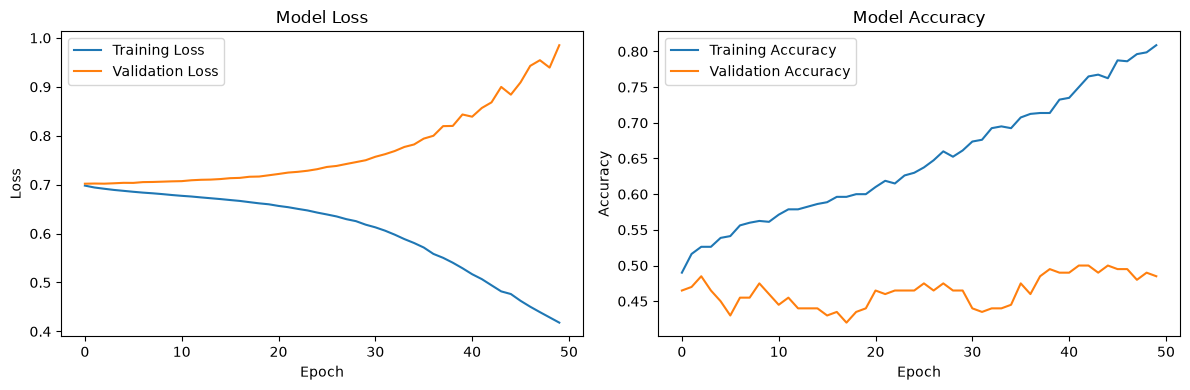

In [18]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import LSTM, Dense, Input
import numpy as np
import matplotlib.pyplot as plt

# Define hyperparameters
sequence_length = 10
input_features = 8
hidden_units = 16
output_size = 1
batch_size = 32
epochs = 50

# Generate synthetic data
X = np.random.randn(1000, sequence_length, input_features)
y = np.random.randint(0, 2, (1000, 1)) # Binary classification

# Define a sequential model
model = Sequential([
    Input(shape=(sequence_length, input_features)), 
    LSTM(units=hidden_units, return_sequences=False),
    Dense(units=output_size, activation='sigmoid')
])
# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
# Print the model summary
model.summary()
# Train the model
history = model.fit(X, y, batch_size=batch_size, epochs=epochs, validation_split=0.2)
# Evaluate the model
test_loss, test_accuracy = model.evaluate(X, y)
print(f"Test accuracy: {test_accuracy:.4f}")
# Make predictions
sample_input = np.random.randn(1, sequence_length, input_features)
prediction = model.predict(sample_input)
print(f"Sample prediction: {prediction[0][0]:.4f}")
# Plot training history
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()